# SiN Meta-Grating Coupler -- Two and Three Meta-Atoms per Period vs the Conventional Grating (Step 3)

Step 2 optimized the **conventional** SiN grating: one unetched tooth and one etched
groove per period. This notebook asks whether a **meta grating**, with several
tooth/groove pairs ("meta-atoms") in each period, couples to an SMF-28 fiber more
efficiently once it is optimized the same way. Two meta gratings are studied:

- **three atoms per period:** six widths and one shared etch depth;
- **two atoms per period:** four widths and one shared etch depth.

Everything except the unit cell is shared with Step 2:

- the platform: 400 nm SiN on the BOX fixed in Step 1, oxide top cladding;
- the period P, fixed by first-order phase matching;
- the constraints: every width ≥ 100 nm (the DUV minimum feature), widths summing to at
  most P, etch depth between 20 nm and the full 400 nm;
- the objective: SMF-28 η at 1.35 µm, with the fiber position re-optimized;
- the optimizer: Meep adjoint gradients and Adam with the same learning-rate schedule;
- the resolutions: optimization at res 60, final evaluation at res 160.

With P fixed, the last groove takes up the slack, so the free parameters number 2 for
the conventional grating, 4 for two atoms and 6 for three atoms.

**What the literature predicts** (`meta/literature.md`): meta-atoms that share one etch depth
change the period's in-plane Fourier content (grating strength, back reflection), but
not its vertical asymmetry. Large directionality gains in the literature come from
scatterers at two heights (dual-etch, L-shaped, overlay gratings). The power budget
therefore decides where any difference comes from:

- **directionality** = up / (up + down): how much of the scattered light goes toward the fiber;
- **mode match** = η / up: how well the up-going beam fits the fiber mode;
- **transmission T:** light that passes the grating without being scattered, i.e. a
  grating that is too weak;
- **L_c:** the 1/e decay length of the emitted intensity along the grating. The overlap
  with the fiber mode is largest for a field decay rate α ≈ 1.37/w₀; the intensity then
  decays as exp(−2αz), so the best L_c = 1/(2α) ≈ w₀/2.74 ≈ 1.7 µm for a 9.2 µm MFD.

## Contents
0. Setup
1. Search strategy
2. Three atoms per period
3. Two atoms per period
4. Comparison with the conventional grating at res 160
5. Design points
6. Conclusion

**Do not use "Run All."** The optimizations take many hours. Every run is checkpointed
in `meta/data/step3_3atoms/` and `meta/data/step3_2atoms/` and resumes or reloads
instead of recomputing.

## 0. Setup

In [1]:
# Imports, style, the Step 1 settings, and the Step 2 conventional baseline.
import json
import pickle
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from pic_toolkit.meep_sim import sin_grating as sg
from pic_toolkit import style
from pic_toolkit.design_points import save_design_point

style.apply_style()
DATA = Path.cwd().parent / "data"
S1 = json.loads((DATA / "step1" / "summary.json").read_text())
S2 = json.loads((DATA / "step2" / "summary.json").read_text())
RES, P, BOX = S1["res_opt"], S1["period_design_um"], S1["box_um"]
ADAM = {"n_iter": 30, "lr0": 0.02, "lr1": 0.002}            # identical to Step 2 (refinement stage)
SCREEN_RES = 40
ADAM_SCREEN = {"n_iter": 15, "lr0": 0.02, "lr1": 0.005}
W_CONV, E_CONV = S2["tooth_um"], S2["etch_um"]
print(f"res {RES}, period {P} um, BOX {BOX} um, {sg.DEFAULT_PARAMS['n_periods']} periods")
print(f"conventional optimum (Step 2): tooth {W_CONV:.4f} um, etch {E_CONV * 1e3:.1f} nm, "
      f"eta {S2['eta_at_res_opt']:.4f} at res {RES}, {S2['res160']['grid']['eta_db']:.2f} dB at res 160")


def common(n_atoms):
    return {"resolution": RES, "period_um": P, "box_um": BOX, "n_atoms": n_atoms}


def from_conventional(w, n, wmin=0.10):
    # Conventional tooth w + groove P - w, with n - 1 features of 100 nm inserted, evenly spaced,
    # into the wider region (narrow teeth inside the groove, or narrow grooves inside the tooth).
    g, k = P - w, n - 1
    if g >= w:
        a = (g - k * wmin) / (k + 1)
        return [w] + [a, wmin] * k + [a]
    t = (w - k * wmin) / (k + 1)
    return [t, wmin] * k + [t, g]


def feasible(w, e, n):
    # Nearest feasible cell (widths >= 100 nm, sum <= P): the same projection Adam uses.
    return list(sg.project(np.array([*w, e]), sg.resolve({**common(n), "widths_um": list(w), "etch_um": e}))[:2 * n])


def make_seeds(n, n_random):
    # Two structured starts and n_random wide-spread random cells (fixed seed, reproducible).
    rng = np.random.default_rng(1)
    d = (0.12, -0.12, 0.04, -0.04)[:2 * n - 2] + (-0.06, 0.06)
    seeds = {"from conventional": (feasible(from_conventional(W_CONV, n), E_CONV, n), E_CONV),
             "near-symmetric": ([P / (2 * n) * (1 + x) for x in d], E_CONV)}
    for k in range(n_random):
        w = 0.10 + rng.dirichlet(0.5 * np.ones(2 * n)) * (P - 0.20 * n)
        seeds[f"random {k + 1}"] = (list(w), float(rng.uniform(0.05, 0.40)))
    for name, (w, e) in seeds.items():
        assert min(w) >= 0.0999 and sum(w) <= P + 1e-9, name
        print(f"{name:>18}: widths {np.round(w, 3)} um, etch {e * 1e3:.0f} nm")
    return seeds


def screen_and_refine(n, seeds, cache):
    # Short Adam runs from every start at the screening resolution, then the best one refined at RES.
    screen = {}
    for name, (w, e) in seeds.items():
        tag = name.replace(" ", "_")
        screen[name] = sg.optimize({**common(n), "resolution": SCREEN_RES, "widths_um": list(w), "etch_um": e},
                                   np.array([*w, e]), cache / f"screen_{tag}.pkl", log=lambda s: None, **ADAM_SCREEN)
    best_name = max(screen, key=lambda k: screen[k]["best"]["eta_best_x0"])
    th0 = screen[best_name]["best"]["theta"]
    refined = sg.optimize({**common(n), "widths_um": list(th0[:2 * n]), "etch_um": float(th0[2 * n])}, th0,
                          cache / f"adam_{best_name.replace(' ', '_')}.pkl", log=lambda s: None, **ADAM)
    return screen, best_name, refined


def show_search(n, screen, best_name, refined):
    # Screening ranking, and both stages' convergence against the conventional optimum.
    for name in sorted(screen, key=lambda k: screen[k]["best"]["eta_best_x0"], reverse=True):
        b = screen[name]["best"]
        print(f"{name:>18}: eta {b['eta_best_x0']:.4f} (res {SCREEN_RES}), widths {np.round(b['theta'][:2 * n], 3)}, "
              f"etch {b['theta'][2 * n] * 1e3:.0f} nm{'   <- refined' if name == best_name else ''}")
    b = refined["best"]
    print(f"refined ({best_name}, res {RES}): eta {b['eta_best_x0']:.4f}, widths {np.round(b['theta'][:2 * n], 4)}, "
          f"etch {b['theta'][2 * n] * 1e3:.1f} nm; conventional optimum at res {RES}: {S2['eta_at_res_opt']:.4f}")
    fig, axes = plt.subplots(1, 2, figsize=(14, 3.8))
    for (name, r), c in zip(screen.items(), style.COLOR_CYCLE * 2):
        axes[0].plot([h["eta_best_x0"] for h in r["history"]], "o-", ms=2.5, color=c,
                     lw=1.8 if name == best_name else 0.8, alpha=1.0 if name == best_name else 0.6, label=name)
    axes[1].plot([h["eta_best_x0"] for h in refined["history"]], "o-", ms=3, color=style.COLOR_CYCLE[0], label=best_name)
    for ax, res_ in zip(axes, (SCREEN_RES, RES)):
        ax.set(xlabel="Adam iteration", ylabel=f"η at 1.35 µm (res {res_})")
    axes[1].axhline(S2["eta_at_res_opt"], color=style.COLOR_REFERENCE, ls="--", label="conventional optimum (Step 2)")
    axes[0].set_title(f"{n} atoms: screening, {len(screen)} starts × {ADAM_SCREEN['n_iter']} steps")
    axes[1].set_title(f"{n} atoms: refinement of the best start")
    axes[0].legend(fontsize=6, ncol=2)
    axes[1].legend(fontsize=8)
    fig.tight_layout()
    plt.show()

res 60, period 0.926 um, BOX 4.58 um, 22 periods
conventional optimum (Step 2): tooth 0.5298 um, etch 202.8 nm, eta 0.3712 at res 60, -4.14 dB at res 160


## 1. Search strategy

With four or six free parameters, Adam can end in different local optima depending on
where it starts. Each meta grating is therefore searched in two stages:

1. **Screening.** Short runs of 15 Adam steps (cosine decay from 20 nm to 5 nm per step)
   from many deliberately different cells, at res 40. Step 1 showed that the
   meta-minus-conventional difference at res 40 is within 0.04 dB of its res-160 value,
   so res 40 ranks candidate cells reliably at less than half the cost of res 60.
2. **Refinement.** The best screened cell is optimized again at res 60, starting from its
   screened optimum, with exactly the settings Step 2 used for the conventional grating
   (30 steps, 20 nm → 2 nm).

The starts are:

- **from the conventional optimum:** its tooth and etch, with the extra 100 nm features
  inserted, evenly spaced, into its wider region. This starts close to the best
  conventional design, so any gain comes from the new freedom;
- **near-symmetric cell:** nearly equal atoms (≈ P/n each). A perfectly symmetric cell
  is a sub-wavelength grating that hardly radiates; a small asymmetry turns on a weak
  first-order grating;
- **random cells with a large spread:** widths drawn from a Dirichlet distribution with a
  small concentration parameter (α = 0.5) on top of the 100 nm floor, so that some atoms
  are wide and others are near the minimum; etch depths uniform in 50–400 nm.

The conventional grating needed no screening stage: with two parameters, Step 2 mapped
its whole landscape directly.

## 2. Three atoms per period

Ten starts (two structured, eight random) are screened, and the best is refined.

> **STOP -- the next cell runs the screening and the refinement (many hours on a first
> run; it reloads from `meta/data/step3_3atoms/` afterwards).**

 from conventional: widths [0.11  0.1   0.11  0.1   0.11  0.396] um, etch 203 nm
    near-symmetric: widths [0.173 0.136 0.161 0.148 0.145 0.164] um, etch 203 nm
          random 1: widths [0.148 0.133 0.131 0.1   0.154 0.26 ] um, etch 209 nm
          random 2: widths [0.101 0.103 0.152 0.117 0.331 0.121] um, etch 106 nm
          random 3: widths [0.102 0.21  0.138 0.101 0.267 0.109] um, etch 228 nm
          random 4: widths [0.124 0.102 0.149 0.103 0.215 0.232] um, etch 146 nm
          random 5: widths [0.1   0.248 0.119 0.204 0.155 0.1  ] um, etch 372 nm
          random 6: widths [0.175 0.134 0.155 0.177 0.175 0.11 ] um, etch 292 nm
          random 7: widths [0.106 0.1   0.134 0.182 0.222 0.182] um, etch 170 nm
          random 8: widths [0.113 0.113 0.209 0.127 0.195 0.169] um, etch 304 nm


          random 2: eta 0.1633 (res 40), widths [0.1   0.149 0.1   0.1   0.377 0.1  ], etch 216 nm   <- refined
          random 3: eta 0.1176 (res 40), widths [0.1   0.216 0.138 0.1   0.272 0.1  ], etch 197 nm
          random 4: eta 0.1162 (res 40), widths [0.1   0.145 0.292 0.1   0.1   0.19 ], etch 180 nm
    near-symmetric: eta 0.1125 (res 40), widths [0.324 0.1   0.1   0.1   0.1   0.164], etch 193 nm
          random 8: eta 0.1035 (res 40), widths [0.1   0.209 0.317 0.1   0.1   0.1  ], etch 174 nm
          random 1: eta 0.1034 (res 40), widths [0.29  0.1   0.1   0.1   0.1   0.236], etch 195 nm
 from conventional: eta 0.0940 (res 40), widths [0.156 0.1   0.157 0.1   0.1   0.312], etch 184 nm
          random 7: eta 0.0892 (res 40), widths [0.1   0.137 0.1   0.221 0.267 0.1  ], etch 183 nm
          random 6: eta 0.0727 (res 40), widths [0.192 0.143 0.1   0.198 0.194 0.1  ], etch 199 nm
          random 5: eta 0.0368 (res 40), widths [0.102 0.254 0.1   0.209 0.162 0.1  ], etch 189 

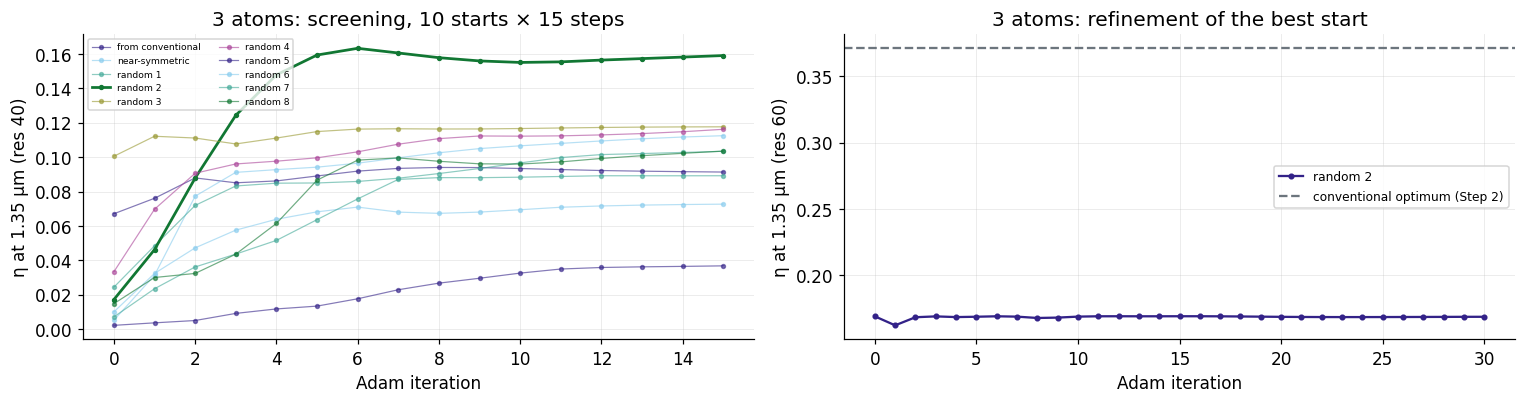

In [2]:
SEEDS3 = make_seeds(3, n_random=8)
screen3, best3, refined3 = screen_and_refine(3, SEEDS3, DATA / "step3_3atoms")
show_search(3, screen3, best3, refined3)

Every three-atom cell, from every start, stays far below the conventional optimum, and
refinement adds little to the best screened cell. Adam drives the cell toward one wide
tooth with the remaining features at the 100 nm minimum, i.e. as close to a
conventional single tooth as the minimum feature size allows. Section 4 shows why in the
power budget.

## 3. Two atoms per period

Two atoms leave features of ~230 nm on average instead of ~150 nm. Four free
parameters need fewer starts: five (two structured, three random) are screened, and the
best is refined.

> **STOP -- the next cell runs the screening and the refinement (many hours on a first
> run; it reloads from `meta/data/step3_2atoms/` afterwards).**

 from conventional: widths [0.215 0.1   0.215 0.396] um, etch 203 nm
    near-symmetric: widths [0.259 0.204 0.218 0.245] um, etch 203 nm
          random 1: widths [0.326 0.255 0.245 0.101] um, etch 238 nm
          random 2: widths [0.32  0.286 0.136 0.184] um, etch 313 nm
          random 3: widths [0.108 0.548 0.163 0.108] um, etch 389 nm


    near-symmetric: eta 0.2748 (res 40), widths [0.394 0.1   0.1   0.245], etch 189 nm   <- refined
 from conventional: eta 0.2663 (res 40), widths [0.367 0.1   0.1   0.359], etch 191 nm
          random 2: eta 0.2112 (res 40), widths [0.384 0.339 0.1   0.103], etch 173 nm
          random 3: eta 0.1124 (res 40), widths [0.111 0.549 0.165 0.1  ], etch 199 nm
          random 1: eta 0.0912 (res 40), widths [0.326 0.256 0.244 0.1  ], etch 205 nm
refined (near-symmetric, res 60): eta 0.3003, widths [0.4816 0.1    0.1    0.2444], etch 225.0 nm; conventional optimum at res 60: 0.3712


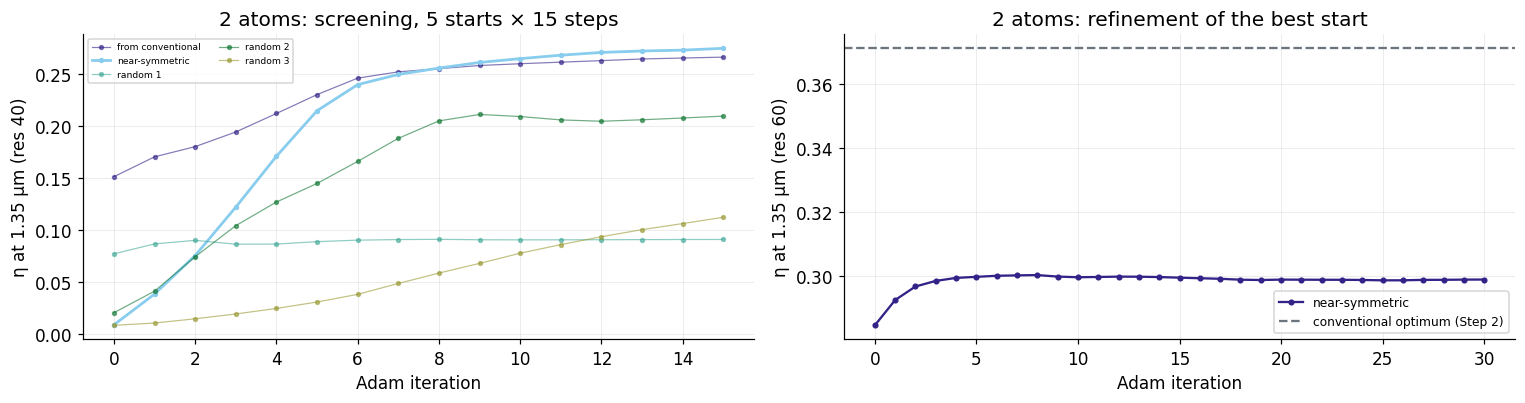

In [3]:
SEEDS2 = make_seeds(2, n_random=3)
screen2, best2, refined2 = screen_and_refine(2, SEEDS2, DATA / "step3_2atoms")
show_search(2, screen2, best2, refined2)

## 4. Comparison with the conventional grating at res 160

All three optimized designs are re-evaluated at res 160 on the `MaterialGrid` (the
reference representation, Step 1) and with Meep `Block`s as an independent cross-check.
The fiber position is re-optimized at 1.35 µm and then held fixed across the band.

In [4]:
# Final res-160 runs of the three optimized designs (the conventional one comes from Step 2).
def best_design(refined, n):
    th = refined["best"]["theta"]
    return {**common(n), "widths_um": [float(x) for x in th[:2 * n]], "etch_um": float(th[2 * n])}


DESIGNS = {"conventional": {**common(1), "widths_um": [W_CONV, P - W_CONV], "etch_um": E_CONV},
           "meta, 2 atoms": best_design(refined2, 2), "meta, 3 atoms": best_design(refined3, 3)}
FINAL = {("conventional", k): pickle.loads((DATA / "step2" / f"final_{k}_res160.pkl").read_bytes()) for k in ("grid", "block")}
for name, folder in (("meta, 2 atoms", "step3_2atoms"), ("meta, 3 atoms", "step3_3atoms")):
    for kind in ("grid", "block"):
        FINAL[(name, kind)] = sg.cached(DATA / folder / f"final_meta_{kind}_res160.pkl",
                                        lambda: sg.run_forward({**DESIGNS[name], "resolution": 160}, kind,
                                                               field_map=(kind == "grid")))


def decay_length(r, i0):
    # 1/e decay length of the emitted |Ey|^2 along the near-field line, fitted past its peak inside the grating.
    x, I = r["x_up"], np.abs(r["ez_up"][i0]) ** 2
    inside = (x > 0) & (x < r["dom"]["x_g1"])
    k = int(np.argmax(np.where(inside, I, 0)))
    sel = inside & (x > x[k]) & (I > 1e-3 * I[k])
    return float(-1 / np.polyfit(x[sel], np.log(I[sel]), 1)[0]) if sel.sum() >= 5 else float("nan")


def report(r):
    # eta at 1.35 um (best fiber position), its spectrum and 1-dB band, and the power budget.
    i0 = int(np.argmin(np.abs(r["wl"] - 1.35)))
    x0, eta = sg.best_x0(r)
    spec = sg.eta_spectrum(r, x0)
    band = r["wl"][spec >= spec.max() * 10 ** -0.1]
    up, down = r["up"][i0], r["down"][i0]
    return {"eta": eta, "eta_db": 10 * np.log10(eta), "spec": spec, "band_1db_nm": 1e3 * (band.max() - band.min()),
            "up": up, "down": down, "R": r["R"][i0], "T": r["T"][i0], "directionality": up / (up + down),
            "mode_match": eta / up, "L_c_um": decay_length(r, i0)}


REP = {key: report(r) for key, r in FINAL.items()}
cols = ["eta", "eta_db", "band_1db_nm", "up", "down", "R", "T", "directionality", "mode_match", "L_c_um"]
print(f"{'':>24}" + "".join(f"{c:>15}" for c in cols))
for (d, k), m in REP.items():
    print(f"{d + ' (' + k + ')':>24}" + "".join(f"{m[c]:>15.4f}" for c in cols))
for name in ("meta, 2 atoms", "meta, 3 atoms"):
    dg = REP[(name, "grid")]["eta_db"] - REP[("conventional", "grid")]["eta_db"]
    db = REP[(name, "block")]["eta_db"] - REP[("conventional", "block")]["eta_db"]
    print(f"{name} - conventional: {dg:+.2f} dB (grid), {db:+.2f} dB (block cross-check)")
    assert REP[(name, "grid")]["eta"] <= REP[(name, "grid")]["up"] + 1e-6

                                    eta         eta_db    band_1db_nm             up           down              R              T directionality     mode_match         L_c_um
     conventional (grid)         0.3853        -4.1419        35.9368         0.5957         0.2226         0.0006         0.1347         0.7280         0.6468        10.0958
    conventional (block)         0.3933        -4.0531        35.9368         0.6022         0.2211         0.0007         0.1308         0.7314         0.6531         9.9766
    meta, 2 atoms (grid)         0.3133        -5.0407        40.9162         0.5092         0.1815         0.0021         0.2889         0.7373         0.6153        18.7261
   meta, 2 atoms (block)         0.3224        -4.9163        40.9162         0.5172         0.1807         0.0025         0.2819         0.7411         0.6233        18.4890
    meta, 3 atoms (grid)         0.1782        -7.4908        30.6841         0.3317         0.1193         0.0047         0.

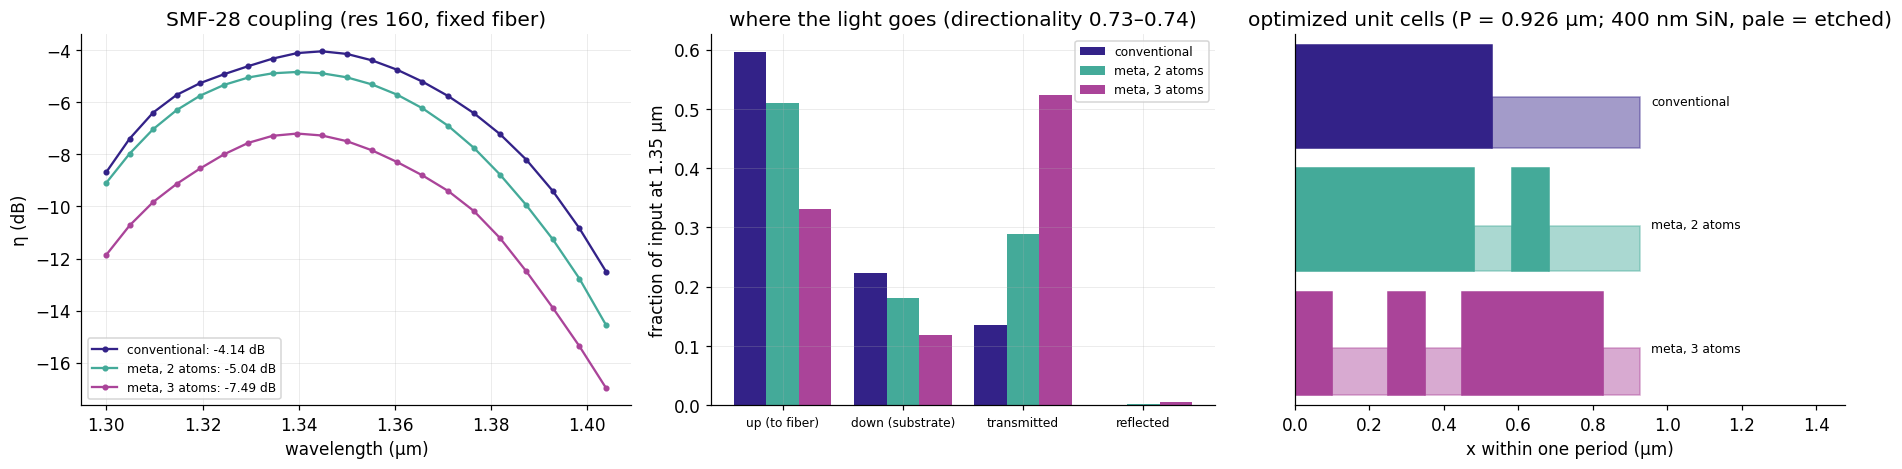

In [5]:
# The comparison figure: spectra, where the light goes, and the optimized unit cells.
NAMES = list(DESIGNS)
COLS = [style.COLOR_CYCLE[0], style.COLOR_CYCLE[2], style.COLOR_CYCLE[5]]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.4), gridspec_kw={"width_ratios": [1.2, 1.1, 1.2]})
for name, c in zip(NAMES, COLS):
    r, m = FINAL[(name, "grid")], REP[(name, "grid")]
    axes[0].plot(r["wl"], 10 * np.log10(m["spec"]), "o-", ms=3, color=c, label=f"{name}: {m['eta_db']:.2f} dB")
axes[0].set(xlabel="wavelength (µm)", ylabel="η (dB)", title="SMF-28 coupling (res 160, fixed fiber)")
axes[0].legend(fontsize=8)
parts = [("up", "up (to fiber)"), ("down", "down (substrate)"), ("T", "transmitted"), ("R", "reflected")]
xb = np.arange(len(parts))
for o, name, c in zip((-0.27, 0.0, 0.27), NAMES, COLS):
    axes[1].bar(xb + o, [REP[(name, "grid")][k] for k, _ in parts], 0.27, color=c, label=name)
axes[1].set_xticks(xb, [lab for _, lab in parts], fontsize=8)
axes[1].set(ylabel="fraction of input at 1.35 µm",
            title=f"where the light goes (directionality {min(REP[(n, 'grid')]['directionality'] for n in NAMES):.2f}–"
                  f"{max(REP[(n, 'grid')]['directionality'] for n in NAMES):.2f})")
axes[1].legend(fontsize=8)
for row, (name, c) in enumerate(zip(NAMES, COLS)):
    dsn = DESIGNS[name]
    w = list(dsn["widths_um"][:-1]) + [P - sum(dsn["widths_um"][:-1])]   # the last groove takes the slack
    x, y0 = 0.0, 2.4 - 1.2 * row
    for k, wk in enumerate(w):
        h = 1.0 if k % 2 == 0 else 1.0 - dsn["etch_um"] / 0.40           # teeth full height, grooves etched
        axes[2].add_patch(plt.Rectangle((x, y0), wk, h, color=c, alpha=1.0 if k % 2 == 0 else 0.45))
        x += wk
    axes[2].text(P + 0.03, y0 + 0.45, name, fontsize=8, va="center")
axes[2].set(xlim=(0, P + 0.55), ylim=(-0.1, 3.5), yticks=[], xlabel="x within one period (µm)",
            title=f"optimized unit cells (P = {P} µm; 400 nm SiN, pale = etched)")
axes[2].grid(False)
fig.tight_layout()
plt.show()

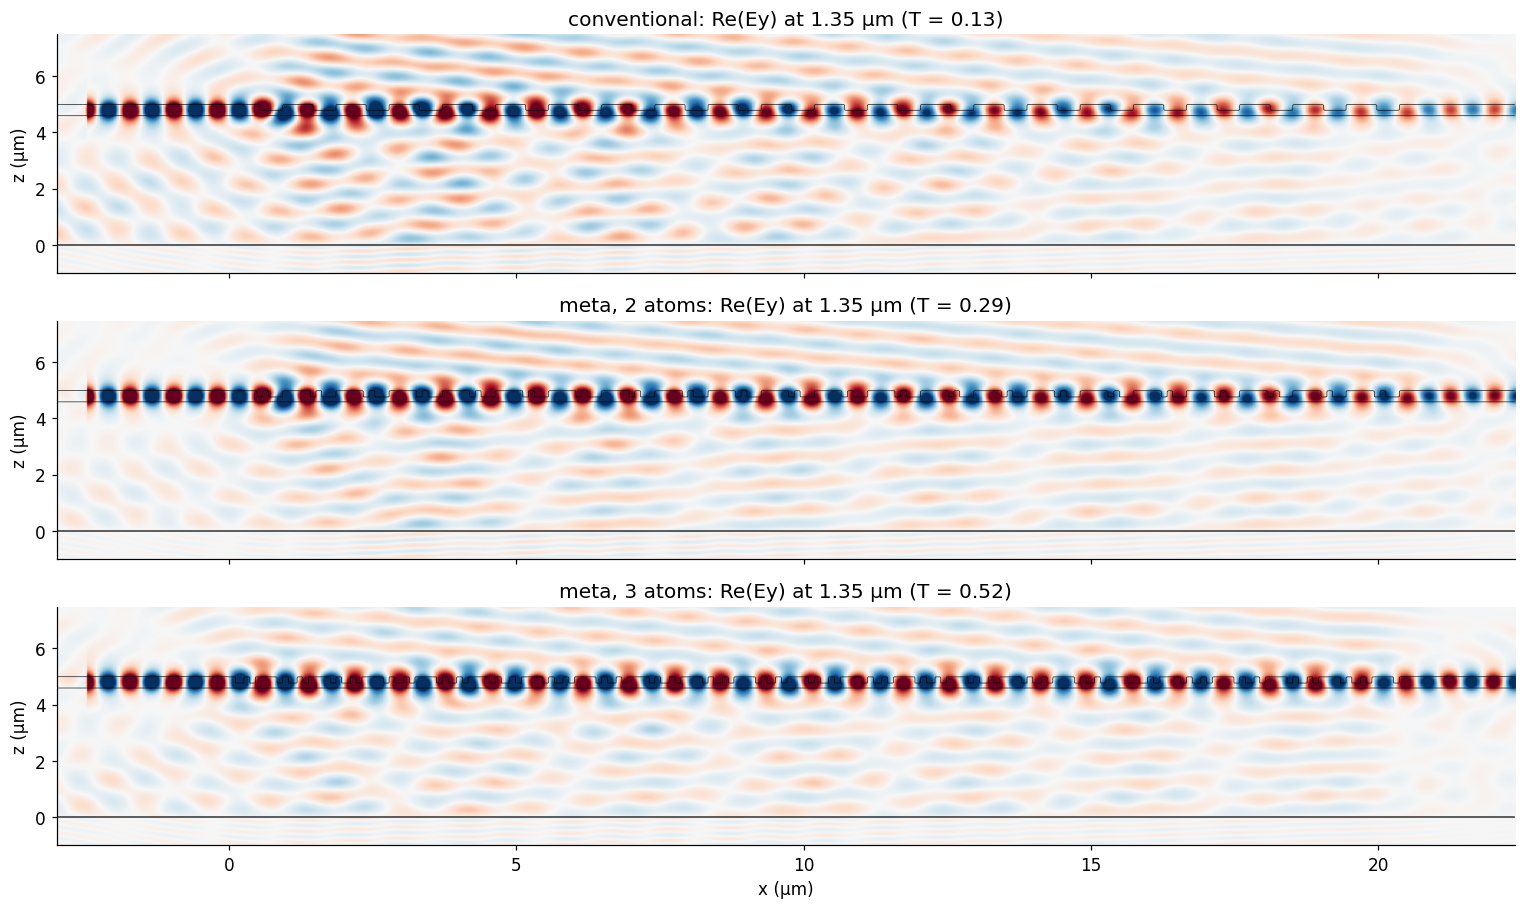

In [6]:
# Re(Ey) at 1.35 um for the three designs: how far along the grating the light is still guided.
fig, axes = plt.subplots(3, 1, figsize=(14, 8.4), sharex=True)
for ax, name in zip(axes, NAMES):
    r = FINAL[(name, "grid")]
    d = r["dom"]
    ext = [d["x_left"], d["x_right"], d["z_sub0"], d["z_top"]]
    f = np.real(r["field_map"]).T
    v = np.abs(f).max() * 0.5
    ax.imshow(f, origin="lower", cmap=style.CMAP_FIELD, vmin=-v, vmax=v, extent=ext, aspect="auto")
    ax.contour(np.linspace(ext[0], ext[1], r["eps_map"].shape[0]), np.linspace(ext[2], ext[3], r["eps_map"].shape[1]),
               r["eps_map"].T, levels=[3.0, 8.0], colors="k", linewidths=0.4)
    ax.set(ylabel="z (µm)", title=f"{name}: Re(Ey) at 1.35 µm (T = {REP[(name, 'grid')]['T']:.2f})")
    ax.grid(False)
axes[-1].set_xlabel("x (µm)")
fig.tight_layout()
plt.show()

> **STOP -- check the comparison before saving.** The grid and block differences should
> agree within the block scatter measured in Step 1, and every design must satisfy
> η ≤ up-going fraction.

## 5. Design points

The three optimized designs are saved with the toolkit's design-point schema in `data/`.

In [7]:
for name, fname in (("conventional", "conventional"), ("meta, 2 atoms", "meta2"), ("meta, 3 atoms", "meta3")):
    dsn, m = DESIGNS[name], REP[(name, "grid")]
    save_design_point(DATA / f"sin_grating_{fname}.yaml", {
        "component": f"sin_grating_coupler_{fname}",
        "parameters": {"core": "SiN 400 nm, n = 2.0", "box_um": BOX, "top": "SiO2", "period_um": P,
                       "n_periods": sg.DEFAULT_PARAMS["n_periods"], "n_atoms": dsn["n_atoms"],
                       "widths_um": [float(x) for x in dsn["widths_um"]], "etch_um": float(dsn["etch_um"]),
                       "fiber": "SMF-28, MFD 9.2 um, 10 deg in oxide", "wavelength_um": 1.35},
        "measured": {k: (v.tolist() if isinstance(v, np.ndarray) else float(v)) for k, v in m.items()},
        "provenance": {"method": f"Meep 2D x-z; adjoint + Adam at res {RES}; evaluated at res 160 (MaterialGrid)",
                       "module": "pic_toolkit.meep_sim.sin_grating"},
        "validation": {"eta_le_up": bool(m["eta"] <= m["up"] + 1e-6),
                       "block_cross_check_eta": float(REP[(name, "block")]["eta"])},
        "rationale": "Adam optimum of eta at 1.35 um under a fixed period, widths >= 100 nm and sum(widths) <= P.",
    })
print("saved:", sorted(p.name for p in DATA.glob("sin_grating_*.yaml")))

saved: ['sin_grating_conventional.yaml', 'sin_grating_meta2.yaml', 'sin_grating_meta3.yaml']


## 6. Conclusion

**On this platform and under these rules, meta-atoms lower the coupling efficiency,
and more atoms lower it more.** The optimized conventional grating reaches −4.14 dB; two
atoms per period reach −5.04 dB (−0.90 dB); three atoms reach −7.49 dB (−3.35 dB). The
block representation gives the same differences within 0.1 dB.

The power budget shows the mechanism:

- **Directionality does not change** (0.73–0.74 for all three). All atoms scatter at the
  same height, so rearranging them in the plane cannot shift power from down to up. This
  matches the literature: directionality gains need scatterers at two heights.
- **The grating gets weaker with every added atom.** Transmission past the grating rises
  from 13 % to 29 % to 52 %, and L_c from 10 µm to 19 µm to 33 µm. The SiN/oxide index
  contrast is small (≈ 0.17 in effective index), and features of 100–230 nm are far below
  the ≈ 0.8 µm guided wavelength. The light sees them averaged into a nearly uniform
  medium, so the period's first-order (radiating) Fourier component weakens. Adam
  responds by building one wide tooth and pushing every other feature to the 100 nm
  minimum, i.e. back toward the conventional single tooth that the minimum feature size
  does not let it reach.
- **Mode match falls** (0.65 → 0.62 → 0.54), because the weaker gratings emit a beam
  that is far longer than the 9.2 µm fiber mode.

**Limits of this study.** The period was fixed from the Bloch index of a 200 nm-etch
reference grating; letting the period vary could raise η for every design. The model is
2D, so lateral mode mismatch is not included (≈ 0.3 dB in the literature benchmark).
Neither caveat favors the meta gratings: their deficit comes from a weaker grating, which a
different period or a 3D model would not restore.

**Where meta-atoms could help instead.** Vertical asymmetry: per-atom etch depths (a
dual-etch or L-shaped cell) or a high-index overlay, as in the literature's
high-directionality couplers, or a higher-contrast platform where 100 nm features are
not averaged away.